# 03 · Modelos

Compara baselines, modelos lineares e de árvore na previsão de `igdb_critic_score`, escolhe um e
prevê os dois grandes lançamentos de novembro de 2026: **GTA VI** e o remake de **The Legend of
Zelda: Ocarina of Time**.

**Divisão temporal**, pela data de lançamento (um split aleatório misturaria passado e futuro):

| Bloco | Período | Uso |
|---|---|---|
| treino | 2010–2021 | ajustar os modelos; validação cruzada temporal para os hiperparâmetros |
| validação | 2022–2023 | comparar os modelos e escolher um |
| teste | jan/2024–ago/2026 | medir o modelo escolhido, sem voltar atrás na escolha |
| desde set/2026 | set/2026 até o jogo mais recente com nota no dataset | conferir o **modelo pronto**, como se as previsões tivessem sido feitas antes do lançamento |

O modelo pronto é ajustado com tudo até agosto de 2026, e é ele que prevê o GTA VI e o Zelda.

Matrizes do notebook 02: `features_linear.parquet` para Ridge e Lasso (média do treino nos
ausentes, dentro do pipeline) e `features.parquet` para Random Forest e LightGBM (ausentes como
estão).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
full = pd.read_parquet(ROOT / "data/processed/features.parquet")
lin = pd.read_parquet(ROOT / "data/processed/features_linear.parquet")
assert full["igdb_id"].equals(lin["igdb_id"])

ID_COLS = ["igdb_id", "name", "slug", "first_release_date", "release_year", "is_upcoming",
           "igdb_critic_score", "igdb_critic_n"]
games = full[ID_COLS].set_index("igdb_id", drop=False)
X_TREE = full.drop(columns=ID_COLS).set_axis(games.index)
X_LIN = lin.drop(columns=ID_COLS).set_axis(games.index)
y = games["igdb_critic_score"]

date = games["first_release_date"]
in_base = ~games["is_upcoming"]
split = pd.Series(pd.NA, index=games.index, dtype="string")
split[in_base & (date < "2022-01-01")] = "treino"
split[in_base & date.between("2022-01-01", "2023-12-31")] = "validação"
split[in_base & date.between("2024-01-01", "2026-08-31")] = "teste"
split[in_base & (date >= "2026-09-01")] = "desde set/2026"  # cresce a cada atualização do dataset

TARGETS = {"GTA VI": "grand-theft-auto-vi", "Zelda: Ocarina of Time": "the-legend-of-zelda-ocarina-of-time--1"}
TARGETS = {label: games.index[games["slug"] == s][0] for label, s in TARGETS.items()}

pd.set_option("display.max_columns", 50)
order = ["treino", "validação", "teste", "desde set/2026"]
summary = games.groupby(split)["igdb_critic_score"].agg(jogos="size", nota_mediana="median").loc[order]
summary["críticos_mediana"] = games.groupby(split)["igdb_critic_n"].median()
summary.round(1)

,jogos,nota_mediana,críticos_mediana
treino,2714,75.4,7.0
validação,225,79.8,5.0
teste,210,83.2,5.0
desde set/2026,8,88.4,4.0


In [2]:
# Estilo dos gráficos: superfície clara, grade discreta, uma cor por papel
BLUE, BLUE_LIGHT, ORANGE = "#2a78d6", "#9ec5f4", "#eb6834"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "figure.figsize": (9, 4.2),
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.labelcolor": INK_2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "legend.frameon": False, "lines.linewidth": 2,
})

## 1. Modelos e hiperparâmetros

- **Média do treino:** prevê sempre a mesma nota. É o piso: um modelo que não bate isso não
  aprendeu nada.
- **Histórico:** a média encolhida da série; sem série, a da desenvolvedora; sem as duas, a da
  publisher. Sem ajuste nenhum, é o palpite de quem acompanha o mercado.
- **Ridge e Lasso:** regressão linear com penalidade, sobre a matriz linear padronizada.
- **Random Forest e LightGBM:** árvores, sobre a matriz completa.

Os hiperparâmetros saem de uma **validação cruzada temporal com janela expansiva** dentro do
treino: cada ano de 2016 a 2021 é previsto por um modelo ajustado com todos os anos anteriores. O
valor escolhido é o de menor MAE médio nos seis anos.

In [3]:
class HistoryBaseline(BaseEstimator, RegressorMixin):
    """Média encolhida da série; sem série, da desenvolvedora; sem as duas, da publisher."""

    def fit(self, X, y):
        return self

    def predict(self, X):
        return np.select([X["serie_n"] > 0, X["dev_n"] > 0], [X["serie_media"], X["dev_media"]], X["pub_media"])


def linear_pipe(model):
    return make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), model)


# nome: (matriz, construtor a partir dos hiperparâmetros, grade)
MODELS = {
    "Média do treino": ("tree", lambda p: DummyRegressor(), {}),
    "Histórico": ("tree", lambda p: HistoryBaseline(), {}),
    "Ridge": ("lin", lambda p: linear_pipe(Ridge(**p)), {"alpha": [1, 10, 30, 100, 300, 1000]}),
    "Lasso": ("lin", lambda p: linear_pipe(Lasso(max_iter=50_000, **p)), {"alpha": [0.01, 0.03, 0.1, 0.3, 1]}),
    "Random Forest": ("tree", lambda p: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0, **p),
                      {"min_samples_leaf": [5, 10, 20], "max_features": [0.3, 0.6]}),
    "LightGBM": ("tree", lambda p: LGBMRegressor(learning_rate=0.03, subsample=0.8, subsample_freq=1,
                                                 colsample_bytree=0.7, random_state=0, verbose=-1, **p),
                 {"num_leaves": [7, 15, 31], "min_child_samples": [20, 50], "n_estimators": [300, 600]}),
}


def fit(name, params, mask):
    kind, make, _ = MODELS[name]
    X = X_LIN if kind == "lin" else X_TREE
    return make(params).fit(X[mask], y[mask])


def predict(name, model, mask):
    X = X_LIN if MODELS[name][0] == "lin" else X_TREE
    return pd.Series(model.predict(X[mask]), index=games.index[mask])


def mae(real, pred):
    return float(np.mean(np.abs(real - pred)))


year = games["release_year"]
cv_rows = []
for name, (_, _, grid) in MODELS.items():
    for params in ParameterGrid(grid):
        errors = []
        for yr in range(2016, 2022):
            fold_fit, fold_val = (split == "treino") & (year < yr), (split == "treino") & (year == yr)
            errors.append(mae(y[fold_val], predict(name, fit(name, params, fold_fit), fold_val)))
        cv_rows.append({"modelo": name, "params": params, "mae_cv": np.mean(errors)})

cv = pd.DataFrame(cv_rows)
best = cv.loc[cv.groupby("modelo", sort=False)["mae_cv"].idxmin()].set_index("modelo")
best.assign(params=best["params"].astype(str)).round(2)

,params,mae_cv
modelo,,
Média do treino,{},8.05
Histórico,{},7.34
Ridge,{'alpha': 1000},7.10
Lasso,{'alpha': 0.3},7.07
Random Forest,"{'max_features': 0.3, 'min_samples_leaf': 10}",7.05
LightGBM,"{'min_child_samples': 50, 'n_estimators': 300,...",6.81


## 2. Validação: escolha do modelo

Cada modelo, com os hiperparâmetros da seção 1, é ajustado no treino e prevê 2022–2023. Além do
MAE e do RMSE:

- **viés:** erro médio (real − previsto). Positivo quer dizer que o modelo prevê notas baixas
  demais;
- **MAE hype alto:** só jogos no topo de hype do ano (`hype_pct_ano` ≥ 0,9), o grupo do GTA VI e
  do Zelda.

In [4]:
high_hype = X_TREE["hype_pct_ano"] >= 0.9


def scores(real, pred):
    err = real - pred
    hh = high_hype[real.index]
    return {"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()), "viés": err.mean(),
            "MAE hype alto": err[hh].abs().mean(), "n hype alto": int(hh.sum())}


def evaluate(fit_mask, pred_mask):
    preds, rows = {}, {}
    for name in MODELS:
        model = fit(name, best.loc[name, "params"], fit_mask)
        preds[name] = predict(name, model, pred_mask)
        rows[name] = scores(y[pred_mask], preds[name])
    return pd.DataFrame(rows).T, pd.DataFrame(preds)


val_scores, val_preds = evaluate(split == "treino", split == "validação")
CHOSEN = val_scores["MAE"].idxmin()
print(f"escolhido na validação: {CHOSEN}")
val_scores.round(2)

escolhido na validação: LightGBM


,MAE,RMSE,viés,MAE hype alto,n hype alto
Média do treino,8.88,10.74,4.51,12.27,40.0
Histórico,8.18,10.07,3.55,10.77,40.0
Ridge,7.53,9.30,3.13,8.79,40.0
Lasso,7.68,9.50,3.31,9.06,40.0
Random Forest,7.47,9.30,2.61,8.81,40.0
LightGBM,7.32,9.26,2.22,8.21,40.0


## 3. Teste

Os modelos são reajustados com treino + validação e preveem jan/2024–ago/2026. Todos aparecem na
tabela para comparação, mas a escolha já foi feita na validação e não muda com o teste. O
intervalo de 95% do MAE vem de bootstrap sobre os jogos do teste.

In [5]:
test_scores, test_preds = evaluate(split.isin(["treino", "validação"]), split == "teste")

rng = np.random.default_rng(0)
abs_err = (y[split == "teste"] - test_preds[CHOSEN]).abs().to_numpy()
boot = rng.choice(abs_err, size=(5000, len(abs_err))).mean(axis=1)
print(f"{CHOSEN} no teste: MAE {abs_err.mean():.2f} (IC 95%: {np.quantile(boot, .025):.2f}–{np.quantile(boot, .975):.2f}) "
      f"em {len(abs_err)} jogos")
test_scores.round(2)

LightGBM no teste: MAE 5.76 (IC 95%: 5.12–6.44) em 210 jogos


,MAE,RMSE,viés,MAE hype alto,n hype alto
Média do treino,9.52,10.98,7.23,10.75,70.0
Histórico,8.26,9.74,5.68,9.18,70.0
Ridge,6.91,8.56,3.92,7.21,70.0
Lasso,6.83,8.44,3.88,7.18,70.0
Random Forest,6.66,8.34,3.34,6.65,70.0
LightGBM,5.76,7.54,1.50,5.26,70.0


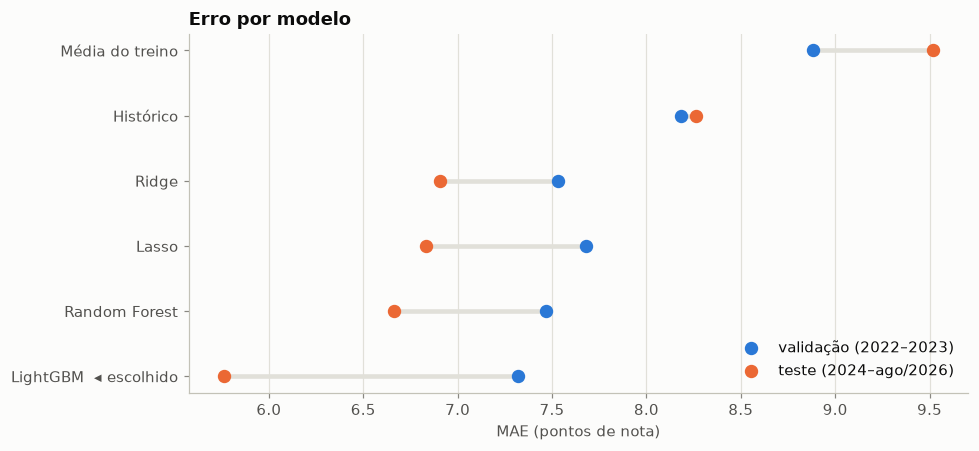

In [6]:
names = list(MODELS)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
yy = np.arange(len(names))
ax.hlines(yy, val_scores.loc[names, "MAE"], test_scores.loc[names, "MAE"], color=GRID, linewidth=3)
ax.scatter(val_scores.loc[names, "MAE"], yy, s=60, color=BLUE, zorder=3, label="validação (2022–2023)")
ax.scatter(test_scores.loc[names, "MAE"], yy, s=60, color=ORANGE, zorder=3, label="teste (2024–ago/2026)")
ax.set_yticks(yy, [f"{n}  ◂ escolhido" if n == CHOSEN else n for n in names])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE (pontos de nota)")
ax.set_title("Erro por modelo")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Previsto × real no teste e o viés por ano em validação + teste. Um viés que cresce com o ano é
a deriva vista no notebook 01: os jogos recentes que já têm 4 críticos são os grandes, e as notas
deles são mais altas que o histórico sugere.

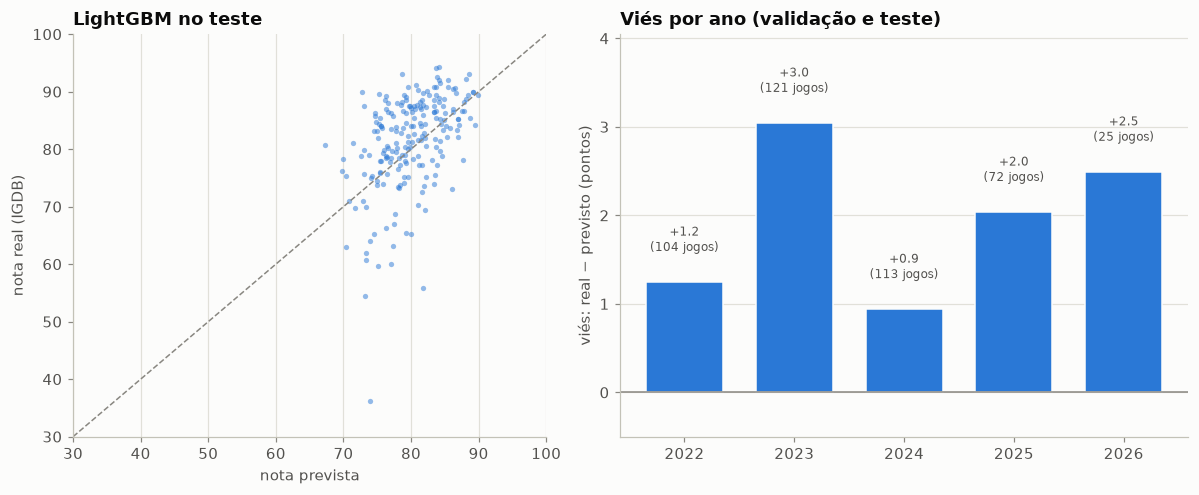

In [7]:
test_real = y[split == "teste"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
ax.scatter(test_preds[CHOSEN], test_real, s=12, color=BLUE, alpha=0.5, linewidths=0)
ax.plot([30, 100], [30, 100], color=MUTED, linewidth=1, linestyle="--")
ax.set_xlim(30, 100); ax.set_ylim(30, 100); ax.grid(axis="both")
ax.set_xlabel("nota prevista"); ax.set_ylabel("nota real (IGDB)")
ax.set_title(f"{CHOSEN} no teste")

ax = axes[1]
res = pd.concat([y[split == "validação"] - val_preds[CHOSEN], test_real - test_preds[CHOSEN]])
by_year = res.groupby(year[res.index]).agg(["mean", "size"])
ax.bar(by_year.index, by_year["mean"], color=np.where(by_year["mean"] > 0, BLUE, ORANGE), width=0.7,
       edgecolor="#fcfcfb", linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
for x, (m, n) in by_year.iterrows():
    ax.text(x, m + (0.3 if m > 0 else -0.3), f"{m:+.1f}\n({n:.0f} jogos)", ha="center",
            va="bottom" if m > 0 else "top", fontsize=8, color=INK_2)
ax.set_ylim(min(0, by_year["mean"].min()) - 0.5, by_year["mean"].max() + 1)
ax.set_xticks(by_year.index)
ax.set_ylabel("viés: real − previsto (pontos)")
ax.set_title("Viés por ano (validação e teste)")
plt.tight_layout(); plt.show()

## 4. Modelo pronto e conferência desde set/2026

O modelo escolhido é reajustado com **tudo até agosto de 2026** e congelado. O intervalo de
previsão de 80% vem dos resíduos do teste (real − previsto, com o modelo que não viu o teste):
vai do percentil 10 ao 90 dos resíduos, somados à previsão. Como os resíduos têm viés, o
intervalo não é simétrico.

A conferência usa todos os jogos lançados de 01/09/2026 em diante que já têm `MIN_CRITICS`+
críticos no dataset. O período não é fixo: ele vai até o jogo mais recente com nota, então cresce
a cada atualização dos dados (`gsp all`, depois os notebooks 02 e 03). Rodar só este notebook
não traz jogos novos.

Os jogos mais recentes têm só 4 ou 5 críticos. A nota "real" deles ainda vai mudar, com um erro
típico de uns 3 pontos para esse número de críticos (notebook 01).


In [8]:
ready_mask = split.isin(["treino", "validação", "teste"])
ready = fit(CHOSEN, best.loc[CHOSEN, "params"], ready_mask)
test_res = test_real - test_preds[CHOSEN]
lo, hi = np.quantile(test_res, [0.1, 0.9])
print(f"intervalo de 80%: previsão {lo:+.1f} a {hi:+.1f} pontos")

hold = split == "desde set/2026"
check = games.loc[hold, ["name", "first_release_date", "igdb_critic_n"]].assign(
    real=y[hold], previsto=predict(CHOSEN, ready, hold))
check["de"], check["até"] = check["previsto"] + lo, check["previsto"] + hi
check["erro"] = check["real"] - check["previsto"]
check["dentro"] = check["real"].between(check["de"], check["até"])
period = f"01/09 a {check['first_release_date'].max():%d/%m/%Y}"
print(f"conferência de {period}: {len(check)} jogos com nota | MAE {check['erro'].abs().mean():.2f} | "
      f"viés {check['erro'].mean():+.2f} | dentro do intervalo: {check['dentro'].sum()} de {len(check)}")
check.assign(first_release_date=check["first_release_date"].dt.strftime("%d/%m")).round(1)

intervalo de 80%: previsão -8.3 a +9.6 pontos
conferência de 01/09 a 22/10/2026: 8 jogos com nota | MAE 3.96 | viés +3.36 | dentro do intervalo: 8 de 8


,name,first_release_date,igdb_critic_n,real,previsto,de,até,erro,dentro
igdb_id,,,,,,,,,
282831,The Blood of Dawnwalker,03/09,4.0,89.5,81.6,73.3,91.2,7.9,True
325602,Onimusha: Way of the Sword,04/09,4.0,84.5,86.9,78.6,96.5,-2.4,True
168667,Marvel's Wolverine,15/09,4.0,87.8,84.3,76.0,93.9,3.5,True
222342,Silent Hill: Townfall,24/09,4.0,84.5,83.4,75.1,93.0,1.1,True
225582,Control Resonant,24/09,5.0,88.2,87.6,79.2,97.1,0.6,True
381247,Ace Combat 8: Wings of Theve,02/10,5.0,90.8,81.6,73.3,91.2,9.2,True
381248,Star Wars: Galactic Racer,06/10,4.0,88.5,82.4,74.1,92.0,6.1,True
405454,Final Fantasy Resonance,22/10,4.0,88.5,87.6,79.2,97.1,0.9,True


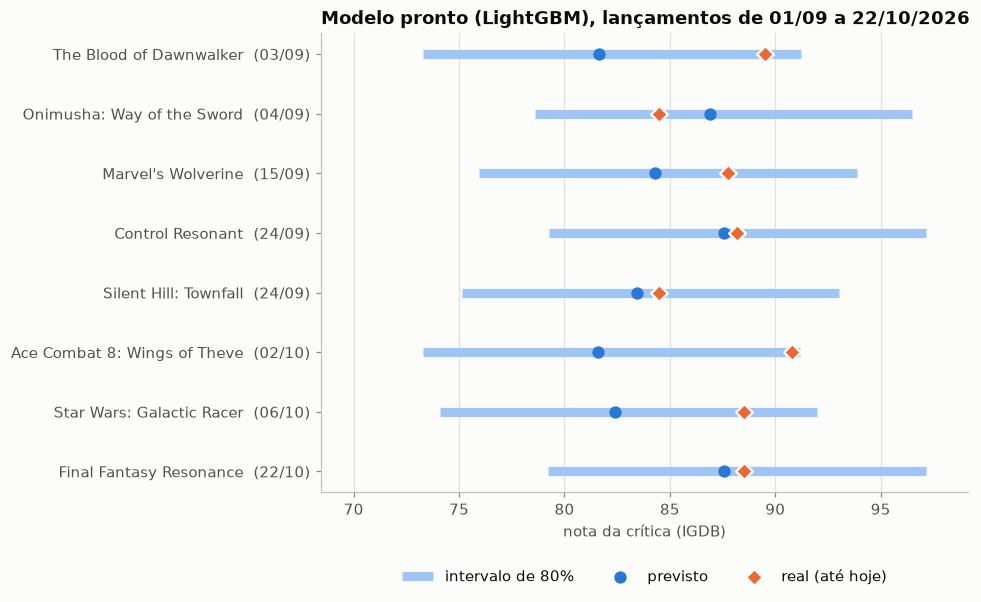

In [9]:
c = check.sort_values("first_release_date", ascending=False).join(X_TREE)
yy = np.arange(len(c))
labels = [f"{n}  ({d:%d/%m})" for n, d in zip(c["name"], c["first_release_date"])]
leg_y = -1.1 / len(c)  # legenda logo abaixo do eixo, qualquer que seja a altura da figura
xlim = c[["de", "até", "real", "serie_media", "dev_media", "pub_media"]].stack().agg(["min", "max"]) + [-2, 2]

fig, ax = plt.subplots(figsize=(9, 0.5 * len(c) + 1.6))
ax.hlines(yy, c["de"], c["até"], color=BLUE_LIGHT, linewidth=6, label="intervalo de 80%")
ax.scatter(c["previsto"], yy, s=50, color=BLUE, zorder=3, label="previsto")
ax.scatter(c["real"], yy, s=60, color=ORANGE, marker="D", zorder=4, edgecolor="#fcfcfb", linewidth=1.5,
           label="real (até hoje)")
ax.set_yticks(yy, labels); ax.set_xlim(xlim)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("nota da crítica (IGDB)")
ax.set_title(f"Modelo pronto ({CHOSEN}), lançamentos de {period}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, leg_y), ncols=3)
plt.tight_layout(); plt.show()


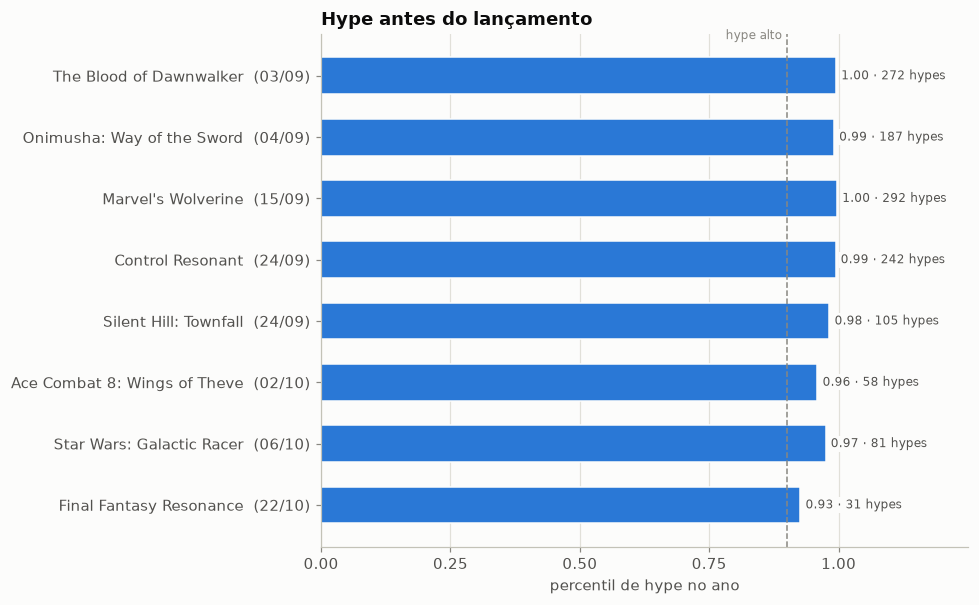

In [10]:
# Hype dos mesmos jogos: o percentil no ano é a feature; os hypes brutos vêm de volta do log(1 + hypes)
fig, ax = plt.subplots(figsize=(9, 0.5 * len(c) + 1.6))
ax.barh(yy, c["hype_pct_ano"].fillna(0), color=BLUE, height=0.6, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0.9, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.89, len(c) - 0.45, "hype alto", color=MUTED, fontsize=8, ha="right", va="bottom")
for yi, pct_, h in zip(yy, c["hype_pct_ano"], np.expm1(c["hype_log"])):
    label = "sem hype" if pd.isna(pct_) else f"{pct_:.2f} · {h:,.0f} hypes".replace(",", ".")
    ax.text((0 if pd.isna(pct_) else pct_) + 0.01, yi, label, va="center", fontsize=8, color=INK_2,
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
ax.set_yticks(yy, labels); ax.set_xlim(0, 1.25); ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("percentil de hype no ano")
ax.set_title("Hype antes do lançamento")
plt.tight_layout(); plt.show()


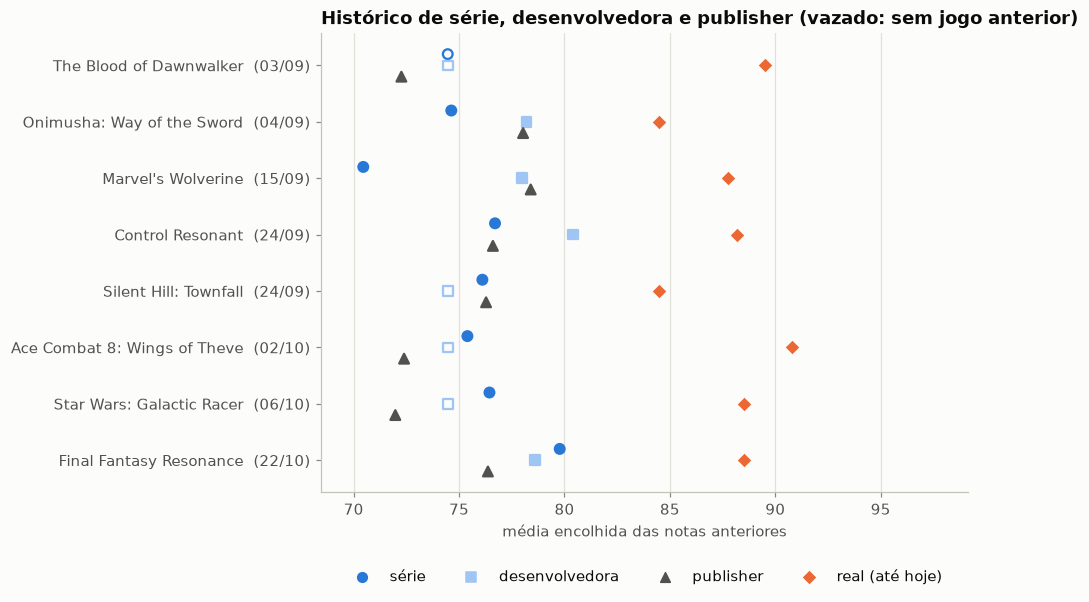

In [11]:
# Histórico dos mesmos jogos, na escala de nota: média encolhida de cada grupo contra a nota real.
# Marcador vazado = grupo sem jogo anterior (vale a média global)
fig, ax = plt.subplots(figsize=(9, 0.5 * len(c) + 1.6))
for (prefix, label, color, marker), dy in zip([("serie", "série", BLUE, "o"),
                                               ("dev", "desenvolvedora", BLUE_LIGHT, "s"),
                                               ("pub", "publisher", INK_2, "^")], [0.2, 0, -0.2]):
    has = c[f"{prefix}_n"] > 0
    ax.scatter(c[f"{prefix}_media"], yy + dy, s=40, marker=marker, zorder=3,
               facecolors=np.where(has, color, "none"), edgecolors=color, linewidths=1.5)
    ax.scatter([], [], s=40, marker=marker, color=color, label=label)  # legenda com o marcador cheio
ax.scatter(c["real"], yy, s=60, color=ORANGE, marker="D", zorder=4, edgecolor="#fcfcfb", linewidth=1.5,
           label="real (até hoje)")
ax.set_yticks(yy, labels); ax.set_xlim(xlim)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("média encolhida das notas anteriores")
ax.set_title("Histórico de série, desenvolvedora e publisher (vazado: sem jogo anterior)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, leg_y), ncols=4)
plt.tight_layout(); plt.show()


In [12]:
# Os mesmos jogos em números: os atributos de hype e histórico e quanto cada bloco de features
# moveu a previsão (contribuições SHAP do LightGBM, em pontos de nota, somadas por bloco)
explainer = ready if CHOSEN == "LightGBM" else fit("LightGBM", best.loc["LightGBM", "params"], ready_mask)
contrib = pd.DataFrame(explainer.predict(X_TREE.loc[c.index], pred_contrib=True),
                       index=c.index, columns=[*X_TREE.columns, "base"])
blocks = {"hype": [f for f in X_TREE.columns if f.startswith("hype_")],
          "histórico": [f for f in X_TREE.columns if f.split("_")[0] in ("dev", "pub", "serie", "pai")]}
blocks["resto"] = [f for f in X_TREE.columns if f not in blocks["hype"] + blocks["histórico"]]

attrs = pd.DataFrame({
    "jogo": c["name"],
    "real": c["real"], "previsto": c["previsto"], "erro": c["erro"],
    "hypes": np.expm1(c["hype_log"]).round(0).astype("Int64"), "hype_pct": c["hype_pct_ano"],
    "série n": c["serie_n"].astype(int), "série média": c["serie_media"], "série última": c["serie_ultima"],
    "dev n": c["dev_n"].astype(int), "dev média": c["dev_media"],
    "pub n": c["pub_n"].astype(int), "pub média": c["pub_media"],
    **{f"Δ {b}": contrib[cols].sum(axis=1) for b, cols in blocks.items()},
}).round(1)
attrs["hype_pct"] = c["hype_pct_ano"].round(2)
attrs.set_index("jogo").iloc[::-1]


,real,previsto,erro,hypes,hype_pct,série n,série média,série última,dev n,dev média,pub n,pub média,Δ hype,Δ histórico,Δ resto
jogo,,,,,,,,,,,,,,,
The Blood of Dawnwalker,89.5,81.6,7.9,272,1.00,0,74.5,NaN,0,74.5,133,72.3,5.6,0.0,1.3
Onimusha: Way of the Sword,84.5,86.9,-2.4,187,0.99,1,74.6,75.1,45,78.2,101,78.0,4.9,4.9,2.4
Marvel's Wolverine,87.8,84.3,3.5,292,1.00,44,70.5,83.6,18,78.0,84,78.4,4.2,2.4,3.0
Control Resonant,88.2,87.6,0.6,242,0.99,1,76.7,83.4,7,80.4,1,76.6,4.5,6.9,1.5
Silent Hill: Townfall,84.5,83.4,1.1,105,0.98,6,76.1,86.4,0,74.5,74,76.3,5.4,2.4,1.0
Ace Combat 8: Wings of Theve,90.8,81.6,9.2,58,0.96,3,75.4,81.3,0,74.5,134,72.4,4.3,0.9,1.7
Star Wars: Galactic Racer,88.5,82.4,6.1,81,0.97,25,76.4,90.8,0,74.5,1,72.0,5.2,1.8,0.6
Final Fantasy Resonance,88.5,87.6,0.9,31,0.93,29,79.8,89.8,8,78.6,137,76.4,3.4,5.9,3.6


## 5. GTA VI e Ocarina of Time

Previsão do modelo pronto, com o intervalo de 80%, e a de cada um dos outros modelos (também
ajustados até agosto de 2026) para ver o quanto eles concordam.

**Sobre o Zelda:** é um remake, e o Ocarina of Time original (1998) não tem nota no IGDB. A
`pai_nota` vem do Metascore (99), convertido para a escala do IGDB no notebook 02. O histórico
da série inclui também o Ocarina of Time 3D (2011).

In [13]:
target_mask = games.index.isin(list(TARGETS.values()))
by_model = {}
for name in MODELS:
    model = ready if name == CHOSEN else fit(name, best.loc[name, "params"], ready_mask)
    by_model[name] = predict(name, model, target_mask)
by_model = pd.DataFrame(by_model).rename(index={v: k for k, v in TARGETS.items()}).rename_axis(None).T

final = by_model.loc[[CHOSEN]].T.rename(columns={CHOSEN: "previsto"})
final["de"], final["até"] = final["previsto"] + lo, final["previsto"] + hi
display(final.round(1))
by_model.round(1)

,previsto,de,até
Zelda: Ocarina of Time,85.2,76.9,94.8
GTA VI,87.1,78.8,96.7


,Zelda: Ocarina of Time,GTA VI
Média do treino,74.7,74.7
Histórico,83.7,84.5
Ridge,88.0,88.5
Lasso,88.2,89.6
Random Forest,83.6,87.8
LightGBM,85.2,87.1


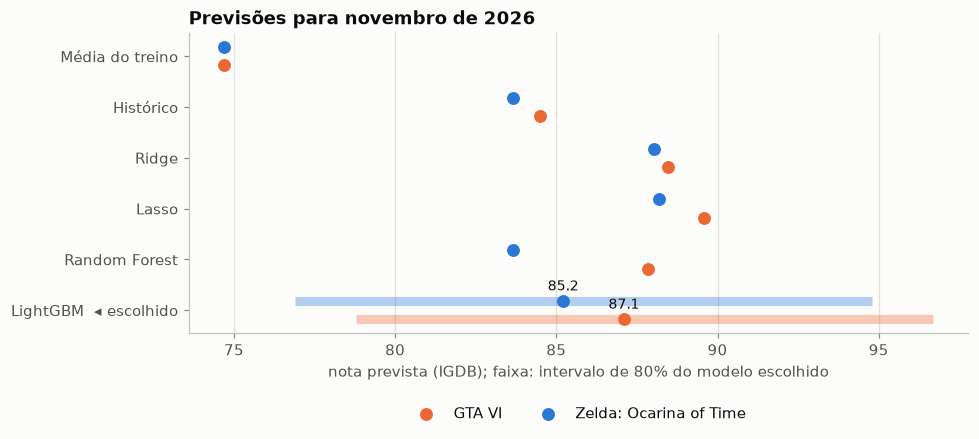

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, (label, color) in enumerate([("GTA VI", ORANGE), ("Zelda: Ocarina of Time", BLUE)]):
    yy = np.arange(len(MODELS)) + (0.18 if k == 0 else -0.18)
    ax.scatter(by_model[label], yy, s=55, color=color, zorder=3, label=label)
    yc = list(MODELS).index(CHOSEN) + (0.18 if k == 0 else -0.18)
    ax.hlines(yc, final.loc[label, "de"], final.loc[label, "até"], color=color, alpha=0.35, linewidth=6)
    ax.annotate(f"{final.loc[label, 'previsto']:.1f}", (final.loc[label, "previsto"], yc), xytext=(0, 7),
                textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_yticks(range(len(MODELS)), [f"{n}  ◂ escolhido" if n == CHOSEN else n for n in MODELS])
ax.invert_yaxis()
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("nota prevista (IGDB); faixa: intervalo de 80% do modelo escolhido")
ax.set_title("Previsões para novembro de 2026")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
plt.tight_layout(); plt.show()

## 6. De onde vem cada previsão

O LightGBM decompõe cada previsão em contribuições por feature (valores SHAP, calculados pelo
próprio LightGBM com `pred_contrib`). A previsão é a nota média do treino mais a soma das
contribuições. As features de valor 0 que pesam são as ausências: ser um jogo sem engine
conhecida, por exemplo.

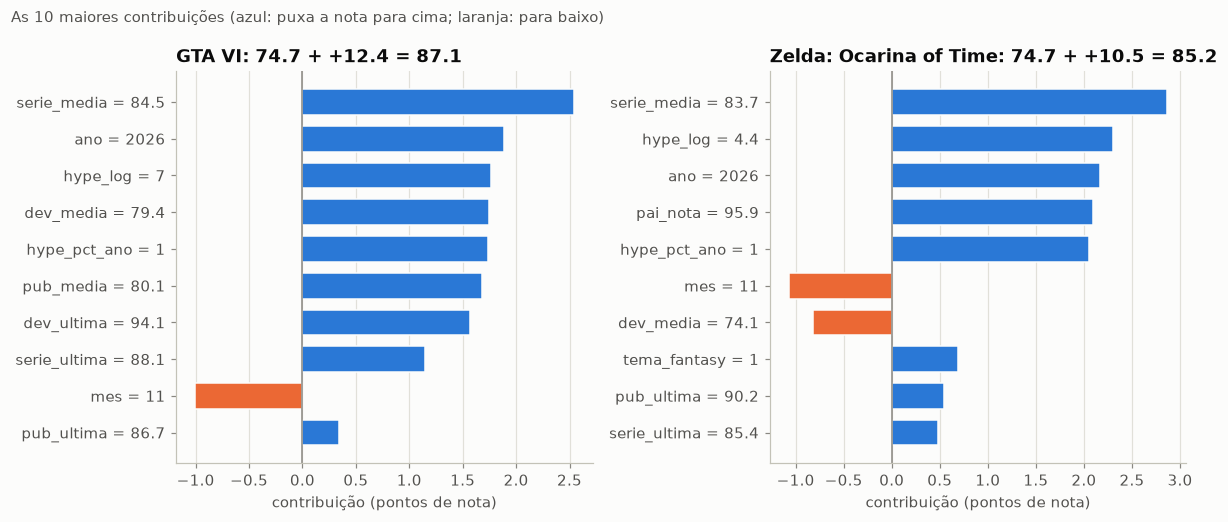

In [15]:
explainer = ready if CHOSEN == "LightGBM" else fit("LightGBM", best.loc["LightGBM", "params"], ready_mask)
contrib = pd.DataFrame(explainer.predict(X_TREE.loc[list(TARGETS.values())], pred_contrib=True),
                       index=list(TARGETS), columns=[*X_TREE.columns, "base"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, label in zip(axes, TARGETS):
    c = contrib.loc[label].drop("base")
    top = c.reindex(c.abs().sort_values().index)[-10:]
    values = X_TREE.loc[TARGETS[label], top.index]
    ax.barh([f"{f} = {v:g}" for f, v in zip(top.index, values.round(1))], top.values,
            color=np.where(top > 0, BLUE, ORANGE), height=0.7, edgecolor="#fcfcfb", linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{label}: {contrib.loc[label, 'base']:.1f} + {c.sum():+.1f} = {contrib.loc[label].sum():.1f}")
    ax.set_xlabel("contribuição (pontos de nota)")
fig.suptitle("As 10 maiores contribuições (azul: puxa a nota para cima; laranja: para baixo)",
             x=0.01, ha="left", fontsize=10, color=INK_2)
plt.tight_layout(); plt.show()

## Próximos passos

- **Deriva:** o viés positivo cresce nos anos recentes (o modelo prevê baixo para jogos
  recentes). Testar peso maior para jogos recentes no ajuste ou uma feature de "tamanho" do
  lançamento que capture a seleção dos jogos com 4+ críticos.
- **Intervalo:** cobriu 8 de 8 na conferência com os dados de 25/10/2026, mas com 8 jogos isso diz
  pouco. Reavaliar com as notas de novembro, quando houver mais jogos e mais críticos por jogo.
- **Registro público** da previsão do GTA VI e do Zelda antes de 05/11/2026 (Zelda) e 19/11/2026
  (GTA VI).